In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [3]:
sns.set_theme(style="whitegrid", context="notebook")

# 1. Carrega e aplica os mesmos filtros de negócio dos notebooks anteriores
df_raw = pd.read_csv("df_corridas.csv")
df = df_raw[
    (df_raw["modalidade"] == "Rua")
    & (df_raw["distancia_km"] >= 2.0)
    & (df_raw["pace_dec"] < 8.0)
].copy()

# 2. Features que definem o "perfil fisiológico e tático" de cada sessão
features = [
    "distancia_km",
    "pace_dec",
    "bpm_medio",
    "pct_tempo_bpm_165+",
    "deriva_cardiaca",
]

# Remove sessões sem sensor completo nas colunas escolhidas
df_cluster = df.dropna(subset=features).reset_index(drop=True)

# 3. Padroniza todas as colunas para média 0 e desvio padrão 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[features])

# Conferência rápida: média deve dar ~0.00 e desvio padrão ~1.00 em todas
df_scaled_check = pd.DataFrame(X_scaled, columns=features)
print(f"Corridas prontas para clusterização: {len(df_cluster)}")
print("\n=== CONFERÊNCIA APÓS STANDARDSCALER ===")
print(df_scaled_check.agg(["mean", "std"]).round(2))

Corridas prontas para clusterização: 196

=== CONFERÊNCIA APÓS STANDARDSCALER ===
      distancia_km  pace_dec  bpm_medio  pct_tempo_bpm_165+  deriva_cardiaca
mean          -0.0       0.0        0.0                -0.0             -0.0
std            1.0       1.0        1.0                 1.0              1.0


 K  Inercia  Silhouette_Score
 2    633.3            0.3401
 3    538.2            0.2280
 4    469.5            0.2231
 5    414.7            0.2228
 6    366.1            0.2368
 7    336.9            0.2457
 8    309.2            0.2338


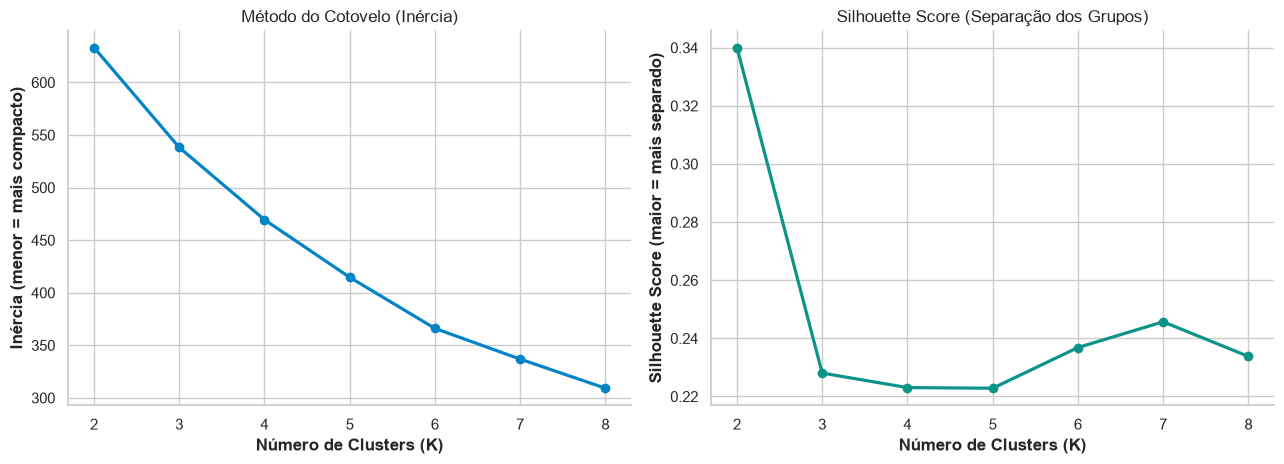

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
inercias = []
silhuetas = []

for k in ks:
  modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = modelo.fit_predict(X_scaled)

  inercias.append(modelo.inertia_)
  silhuetas.append(silhouette_score(X_scaled, labels))

# Tabela rápida para comparar os números exatos
df_metricas_k = pd.DataFrame({
    "K": list(ks),
    "Inercia": np.round(inercias, 1),
    "Silhouette_Score": np.round(silhuetas, 4),
})
print(df_metricas_k.to_string(index=False))

# Gráfico duplo: Cotovelo à esquerda, Silhueta à direita
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

ax1.plot(ks, inercias, marker="o", linewidth=2.3, color="#0284C7")
ax1.set_title("Método do Cotovelo (Inércia)")
ax1.set_xlabel("Número de Clusters (K)", fontweight="bold")
ax1.set_ylabel("Inércia (menor = mais compacto)", fontweight="bold")
ax1.set_xticks(list(ks))

ax2.plot(ks, silhuetas, marker="o", linewidth=2.3, color="#0D9488")
ax2.set_title("Silhouette Score (Separação dos Grupos)")
ax2.set_xlabel("Número de Clusters (K)", fontweight="bold")
ax2.set_ylabel("Silhouette Score (maior = mais separado)", fontweight="bold")
ax2.set_xticks(list(ks))

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

In [5]:
def fmt_pace(val):
  if pd.isna(val) or val <= 0:
    return ""
  seg = int(round(val * 60))
  return f"{seg // 60}:{seg % 60:02d}"


# 1. Treina o modelo final com K = 4
K_ESCOLHIDO = 4
kmeans = KMeans(n_clusters=K_ESCOLHIDO, random_state=42, n_init=10)
df_cluster["cluster"] = kmeans.fit_predict(X_scaled)

# 2. Perfil médio de cada cluster na escala real (humana)
perfil_clusters = (
    df_cluster.groupby("cluster")
    .agg(
        qtd_corridas=("record_id", "count"),
        dist_media_km=("distancia_km", "mean"),
        pace_medio_dec=("pace_dec", "mean"),
        bpm_medio=("bpm_medio", "mean"),
        pct_bpm_165=("pct_tempo_bpm_165+", "mean"),
        deriva_cardiaca=("deriva_cardiaca", "mean"),
        peso_medio_kg=("peso_kg", "mean"),
    )
    .round(2)
)

perfil_clusters["pace_medio"] = perfil_clusters["pace_medio_dec"].apply(fmt_pace)

cols_perfil = [
    "qtd_corridas",
    "dist_media_km",
    "pace_medio",
    "bpm_medio",
    "pct_bpm_165",
    "deriva_cardiaca",
    "peso_medio_kg",
]
print("=== PERFIL MÉDIO DE CADA CLUSTER (ESCALA REAL) ===")
print(perfil_clusters[cols_perfil].to_string())

# 3. Evolução temporal: quantas corridas de cada ano caíram em cada grupo
print("\n=== DISTRIBUIÇÃO DOS CLUSTERS POR ANO ===")
print(pd.crosstab(df_cluster["cluster"], df_cluster["ano"], margins=True))

=== PERFIL MÉDIO DE CADA CLUSTER (ESCALA REAL) ===
         qtd_corridas  dist_media_km pace_medio  bpm_medio  pct_bpm_165  deriva_cardiaca  peso_medio_kg
cluster                                                                                                
0                  61           4.58       7:07     145.16         4.09             1.06          85.32
1                  36           4.53       6:43     159.89        38.43             1.04          84.12
2                  43           6.44       5:35     165.37        63.82             1.09          79.32
3                  56           7.09       6:20     148.50         7.16             1.05          80.84

=== DISTRIBUIÇÃO DOS CLUSTERS POR ANO ===
ano      2024  2025  2026  All
cluster                       
0           0    15    46   61
1           4    25     7   36
2          12     5    26   43
3           3     4    49   56
All        19    49   128  196


Variância explicada: PC1 = 48.9% | PC2 = 20.6% (Total preservado em 2D = 69.4%)

=== PESO DAS VARIÁVEIS NOS EIXOS DO PCA ===
                      PC1    PC2
distancia_km        0.221  0.845
pace_dec           -0.484 -0.268
bpm_medio           0.573 -0.302
pct_tempo_bpm_165+  0.587 -0.306
deriva_cardiaca     0.209  0.172


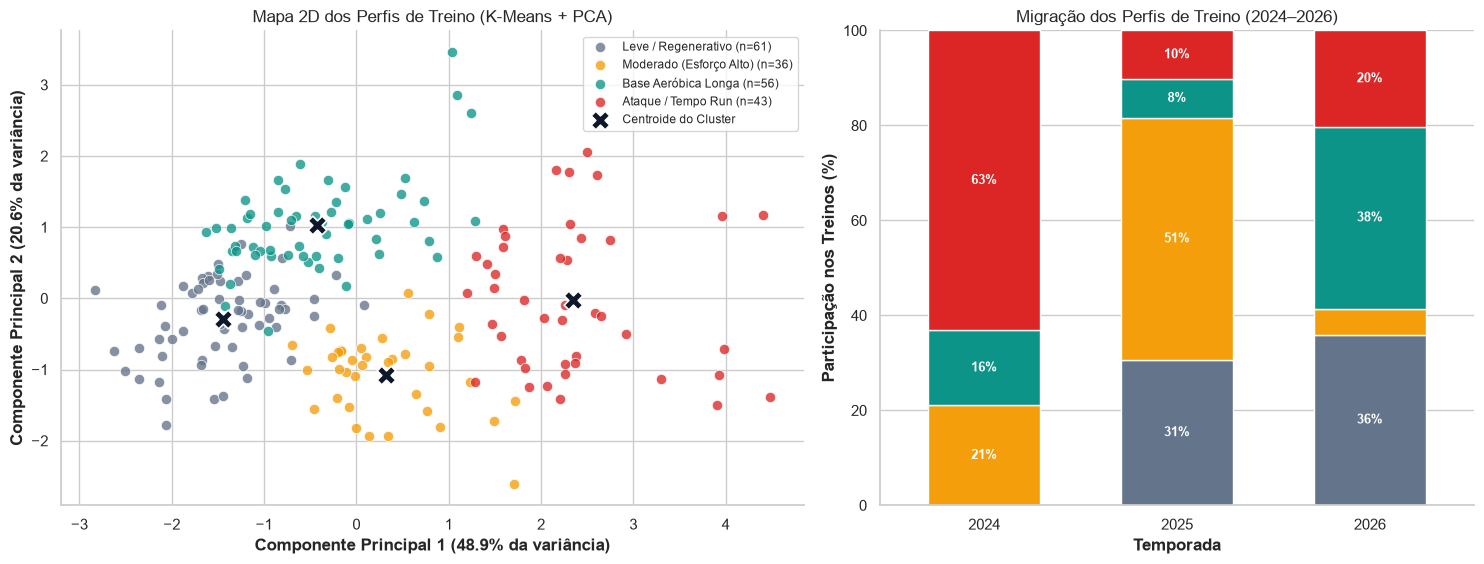

In [6]:
from pathlib import Path
from sklearn.decomposition import PCA

PASTA_IMAGENS = Path("images")
PASTA_IMAGENS.mkdir(exist_ok=True)

# 1. Batiza cada número de cluster com o perfil fisiológico descoberto
nomes_clusters = {
    0: "Leve / Regenerativo",
    1: "Moderado (Esforço Alto)",
    3: "Base Aeróbica Longa",
    2: "Ataque / Tempo Run",
}

ordem_perfis = [
    "Leve / Regenerativo",
    "Moderado (Esforço Alto)",
    "Base Aeróbica Longa",
    "Ataque / Tempo Run",
]

paleta_perfis = {
    "Leve / Regenerativo": "#64748B",  # Ardósia
    "Moderado (Esforço Alto)": "#F59E0B",  # Âmbar
    "Base Aeróbica Longa": "#0D9488",  # Verde-petróleo
    "Ataque / Tempo Run": "#DC2626",  # Vermelho
}

df_cluster["perfil_treino"] = pd.Categorical(
    df_cluster["cluster"].map(nomes_clusters),
    categories=ordem_perfis,
    ordered=True,
)

# 2. Aplica PCA para projetar as 5 variáveis em 2 dimensões visuais
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_scaled)

df_cluster["PC1"] = coords_pca[:, 0]
df_cluster["PC2"] = coords_pca[:, 1]

var_pc1, var_pc2 = pca.explained_variance_ratio_ * 100
print(
    f"Variância explicada: PC1 = {var_pc1:.1f}% | PC2 = {var_pc2:.1f}% "
    f"(Total preservado em 2D = {var_pc1 + var_pc2:.1f}%)"
)

# Mostra o peso de cada variável original na formação de PC1 e PC2
pesos_pca = pd.DataFrame(
    pca.components_.T, index=features, columns=["PC1", "PC2"]
).round(3)
print("\n=== PESO DAS VARIÁVEIS NOS EIXOS DO PCA ===")
print(pesos_pca.to_string())

# 3. Painel Duplo: Mapa 2D dos Clusters (PCA) + Evolução Proporcional por Ano
fig, (ax_pca, ax_evol) = plt.subplots(
    1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.25, 1]}
)

# Esquerda: Dispersão PCA
for perfil in ordem_perfis:
  sub = df_cluster[df_cluster["perfil_treino"] == perfil]
  ax_pca.scatter(
      sub["PC1"],
      sub["PC2"],
      color=paleta_perfis[perfil],
      label=f"{perfil} (n={len(sub)})",
      alpha=0.78,
      s=55,
      edgecolors="white",
      linewidth=0.6,
  )

# Projeta também os centros (centroides) dos 4 grupos no plano PCA
centroides_2d = pca.transform(kmeans.cluster_centers_)
ax_pca.scatter(
    centroides_2d[:, 0],
    centroides_2d[:, 1],
    marker="X",
    s=180,
    color="#0F172A",
    edgecolors="white",
    linewidth=1.2,
    zorder=5,
    label="Centroide do Cluster",
)

ax_pca.set_xlabel(f"Componente Principal 1 ({var_pc1:.1f}% da variância)", fontweight="bold")
ax_pca.set_ylabel(f"Componente Principal 2 ({var_pc2:.1f}% da variância)", fontweight="bold")
ax_pca.set_title("Mapa 2D dos Perfis de Treino (K-Means + PCA)")
ax_pca.legend(frameon=True, loc="best", fontsize=8.8)

# Direita: Barras 100% empilhadas mostrando a mudança de perfil entre 2024, 2025 e 2026
prop_ano = (
    pd.crosstab(df_cluster["ano"], df_cluster["perfil_treino"], normalize="index")
    * 100
)[ordem_perfis]

prop_ano.plot(
    kind="bar",
    stacked=True,
    color=[paleta_perfis[p] for p in ordem_perfis],
    width=0.58,
    ax=ax_evol,
    legend=False,
)

# Escreve os percentuais maiores que 8% dentro de cada bloco da barra
for idx_ano, (_, row) in enumerate(prop_ano.iterrows()):
  acumulado = 0.0
  for perfil in ordem_perfis:
    val = row[perfil]
    if val >= 8.0:
      ax_evol.text(
          idx_ano,
          acumulado + val / 2.0,
          f"{val:.0f}%",
          ha="center",
          va="center",
          color="white",
          fontweight="bold",
          fontsize=9.5,
      )
    acumulado += val

ax_evol.set_ylim(0, 100)
ax_evol.set_xlabel("Temporada", fontweight="bold")
ax_evol.set_ylabel("Participação nos Treinos (%)", fontweight="bold")
ax_evol.set_title("Migração dos Perfis de Treino (2024–2026)")
ax_evol.tick_params(axis="x", rotation=0)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "09_clusters_kmeans_pca_evolucao.png")
plt.show()